In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv')

In [5]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [6]:
df.columns = df.columns.str.lower()
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [7]:
df.status.value_counts()

,count
status,
1,3200
2,1254
0,1


In [8]:
status_values = {
    1: 'ok',
    2:"default",
    0:'unk'
    }
# df.status = df.status.map(status_values)
df.status = df.status.map(status_values)

In [9]:
df.status

,status
0,ok
1,ok
2,default
3,ok
4,ok
...,...
4450,default
4451,ok
4452,default
4453,ok


In [10]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,1,60,30,2,1,3,73,129,0,0,800,846
1,ok,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,default,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,ok,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,ok,0,1,36,26,1,1,1,46,107,0,0,310,910


In [11]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}
df.job = df.job.map(job_values)

In [12]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [13]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [14]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [15]:
df.describe()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.000000,4455.000000,4455.000000,4455.000000,4421.000000,4408.000000,4437.000000,4455.000000,4455.000000
mean,7.987205,46.441751,37.077666,55.568799,130.568197,5403.433984,342.948614,1039.021773,1462.875645
std,8.173444,14.655225,10.984856,19.515878,86.367434,11573.161523,1245.861736,474.543007,628.089913
min,0.000000,6.000000,18.000000,35.000000,0.000000,0.000000,0.000000,100.000000,105.000000
25%,2.000000,36.000000,28.000000,35.000000,80.000000,0.000000,0.000000,700.000000,1117.500000
50%,5.000000,48.000000,36.000000,51.000000,120.000000,3000.000000,0.000000,1000.000000,1400.000000
75%,12.000000,60.000000,45.000000,72.000000,165.000000,6000.000000,0.000000,1300.000000,1692.000000
max,48.000000,72.000000,68.000000,180.000000,959.000000,300000.000000,30000.000000,5000.000000,11140.000000


In [16]:
df.status.value_counts()

,count
status,
ok,3200
default,1254
unk,1


In [17]:
df = df[df.status != 'unk'].reset_index(drop=True)

In [18]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [20]:
y_train = (df_train.status == 'default').astype('int')
y_test = (df_test.status == 'default').astype('int')
y_val = (df_val.status == 'default').astype('int')

In [21]:
del df_train['status']
del df_val['status']
del df_test['status']

In [22]:
df_train

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,18,private,36,45,married,no,fixed,45,220.0,20000.0,0.0,800,1600
2668,7,private,60,29,married,no,fixed,60,51.0,3500.0,500.0,1000,1290
2669,1,parents,24,19,single,no,fixed,35,28.0,0.0,0.0,400,600
2670,15,owner,48,43,married,no,freelance,60,100.0,18000.0,0.0,2500,2976


##### Decision Tree:

In [23]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

In [24]:
df_train.iloc[0].to_dict()

{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

In [25]:
xi = df_train.iloc[0].to_dict()

In [26]:
assess_risk(xi)

'ok'

In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer

In [28]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [29]:
dv = DictVectorizer(sparse=False)
x_train = dv.fit_transform(train_dicts)

In [30]:
train_dicts[1]

{'seniority': 6,
 'home': 'parents',
 'time': 48,
 'age': 32,
 'marital': 'single',
 'records': 'yes',
 'job': 'fixed',
 'expenses': 35,
 'income': 85.0,
 'assets': 0.0,
 'debt': 0.0,
 'amount': 1100,
 'price': 1330}

In [31]:
x_train[1]

array([3.20e+01, 1.10e+03, 0.00e+00, 0.00e+00, 3.50e+01, 0.00e+00,
       0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
       8.50e+01, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
       0.00e+00, 0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00,
       1.33e+03, 0.00e+00, 1.00e+00, 6.00e+00, 4.80e+01])

In [32]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [33]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [34]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
x_val = dv.transform(val_dicts)

In [35]:
y_pred = dt.predict_proba(x_val)[:, 1]

In [36]:
y_pred

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 0.,
       0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
       1., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0., 0.,
       0., 1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0., 0., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0.,
       1., 0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 0., 1., 1., 1., 0., 0.,
       0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 0., 1.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0.,
       0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 1.,
       0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 0., 0., 0.

In [37]:
from sklearn.metrics import roc_auc_score

In [38]:
roc_auc_score(y_val, y_pred)

np.float64(0.6624446005182727)

In [39]:
y_pred = dt.predict_proba(x_train)[:, 1]

In [40]:
roc_auc_score(y_train, y_pred)

## overfitting

np.float64(1.0)

In [41]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [42]:
y_pred = dt.predict_proba(x_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(x_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

train: 0.7054989859726213
val: 0.6685264343319367


In [43]:
from sklearn.tree import export_text

In [44]:
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1



##### Decision Tree Learning:

In [45]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000, 500, 'ok'],
    [3000, 2000, 'default'],
]


df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])
df_example

,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


In [46]:
df_example.sort_values('debt')

,assets,debt,status
6,9000,500,ok
1,2000,1000,default
3,5000,1000,ok
2,0,1000,default
5,4000,1000,ok
4,5000,1000,ok
7,3000,2000,default
0,8000,3000,default


In [47]:
Ts = [0, 2000, 3000, 4000, 5000, 8000]

In [48]:
from IPython.display import display

In [49]:
for t in Ts:
    print(t)
    df_left  = df_example[df_example.assets <= t]
    df_right = df_example[df_example.assets > t]

    display(df_left)
    print(df_left.status.value_counts(normalize=True))
    display(df_right)
    print(df_right.status.value_counts(normalize=True))
    print()

0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


...

status
default    0.5
ok         0.5
Name: proportion, dtype: float64

8000


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,debt,status
6,9000,500,ok


status
ok    1.0
Name: proportion, dtype: float64



In [50]:
thresholds = {
    'assets' : [0, 2000, 3000, 4000, 5000, 8000],
    'debt' : [500, 1000, 2000]
}

In [51]:
for ft, Ts in thresholds.items():
    print('#############')
    print(ft)
    for t in Ts:
        print(t)
        df_left  = df_example[df_example[ft] <= t]
        df_right = df_example[df_example[ft] > t]

        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))
        print()



#############
assets
0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


...

status
default    1.0
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64



For F in features:
    find all thresholds for F
    for t in thresholds:
        split data using 'f>t' condition
        compute impurity of split

##### Parameter Tuning:

In [52]:
for d in [1, 2, 3, 4, 5, 6, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(x_train, y_train)
    y_pred = dt.predict_proba(x_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    print('%4s -> %.3f' % (d, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.767
   6 -> 0.751
  10 -> 0.699
  15 -> 0.661
  20 -> 0.652
None -> 0.663


In [53]:
scores = []
for d in [4, 5, 6, 7, 10, 15, 20, None]:
    for s in [1, 2, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=d)
        dt.fit(x_train, y_train)
        y_pred = dt.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        print('(%4s, %3d) -> %.3f' % (d, s, auc))
        scores.append((d, s, auc))

(   4,   1) -> 0.761
(   4,   2) -> 0.761
(   4,   5) -> 0.761
(   4,  10) -> 0.761
(   4,  15) -> 0.761
(   4,  20) -> 0.761
(   4, 100) -> 0.761
(   4, 200) -> 0.761
(   4, 500) -> 0.761
(   5,   1) -> 0.766
(   5,   2) -> 0.766
(   5,   5) -> 0.766
(   5,  10) -> 0.767
(   5,  15) -> 0.766
(   5,  20) -> 0.767
(   5, 100) -> 0.767
(   5, 200) -> 0.767
(   5, 500) -> 0.767
(   6,   1) -> 0.757
(   6,   2) -> 0.761
(   6,   5) -> 0.746
(   6,  10) -> 0.750
(   6,  15) -> 0.760
(   6,  20) -> 0.748
(   6, 100) -> 0.751
(   6, 200) -> 0.751
(   6, 500) -> 0.750
(   7,   1) -> 0.735
(   7,   2) -> 0.750
(   7,   5) -> 0.739
(   7,  10) -> 0.747
(   7,  15) -> 0.753
(   7,  20) -> 0.739
(   7, 100) -> 0.754
(   7, 200) -> 0.748
(   7, 500) -> 0.744
(  10,   1) -> 0.693
(  10,   2) -> 0.686
(  10,   5) -> 0.692
(  10,  10) -> 0.692
(  10,  15) -> 0.682
(  10,  20) -> 0.702
(  10, 100) -> 0.693
(  10, 200) -> 0.697
(  10, 500) -> 0.675
(  15,   1) -> 0.664
(  15,   2) -> 0.666
(  15,   5) -

In [54]:
column = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=column)
df_scores.head()


,max_depth,min_samples_leaf,auc
0,4.0,1,0.761283
1,4.0,2,0.761283
2,4.0,5,0.761283
3,4.0,10,0.761283
4,4.0,15,0.761283


In [55]:
df_scores.sort_values(by='auc', ascending=False).head()

,max_depth,min_samples_leaf,auc
16,5.0,200,0.766938
12,5.0,10,0.766938
15,5.0,100,0.766938
17,5.0,500,0.766938
14,5.0,20,0.766938


In [56]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot

auc                                                    \
max_depth              NaN      4.0       5.0       6.0       7.0       10.0   
min_samples_leaf                                                               
1                 0.654531  0.761283  0.766496  0.757462  0.734709  0.693323   
2                 0.654044  0.761283  0.766496  0.761104  0.749761  0.685873   
5                 0.669301  0.761283  0.766496  0.746240  0.739392  0.691915   
10                0.651347  0.761283  0.766938  0.750303  0.746815  0.691670   
15                0.649445  0.761283  0.766496  0.760414  0.753251  0.681719   
20                0.641971  0.761283  0.766938  0.748453  0.739274  0.701636   
100               0.643563  0.761283  0.766938  0.750836  0.753615  0.693226   
200               0.661648  0.761283  0.766938  0.751141  0.748417  0.697159   
500               0.650242  0.761283  0.766938  0.749879  0.744227  0.675117   

                                      
max_depth             15.0      20.0  
min_samples_leaf                      
1                 0.664488  0.651964  
2                 0.666344  0.655636  
5                 0.670173  0.651704  
10                0.665405  0.653248  
15                0.659087  0.642946  
20                0.652818  0.644051  
100               0.661010  0.669919  
200               0.661385  0.667043  
500               0.660092  0.654661

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

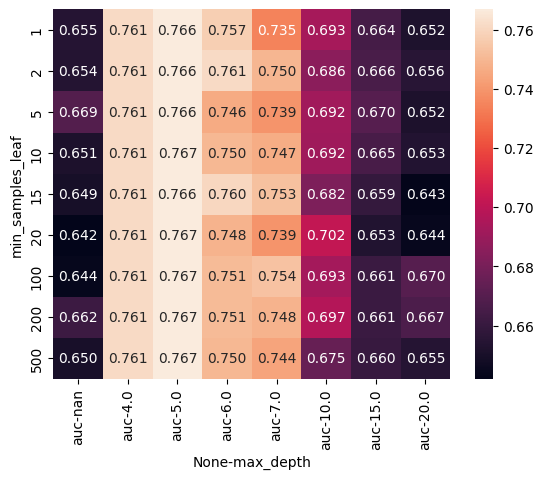

In [57]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [58]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(x_train, y_train)


DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)

##### Ensembles and random forest:

In [59]:
from sklearn.ensemble import RandomForestClassifier

In [60]:
rf = RandomForestClassifier(n_estimators = 10, random_state = 1)
rf.fit(x_train, y_train)

RandomForestClassifier(n_estimators=10, random_state=1)

In [61]:
y_pred = rf.predict_proba(x_val)[:, 1]

In [62]:
roc_auc_score(y_val, y_pred)

np.float64(0.7744726453706618)

In [63]:
scores = []
for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators = n, random_state = 1)
    rf.fit(x_train, y_train)
    y_pred = rf.predict_proba(x_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append([n, auc])

In [64]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])

In [65]:
df_scores

,n_estimators,auc
0,10,0.774473
1,20,0.803532
2,30,0.815075
3,40,0.815686
4,50,0.817082
5,60,0.816458
6,70,0.817321
7,80,0.816307
8,90,0.816824
9,100,0.817599


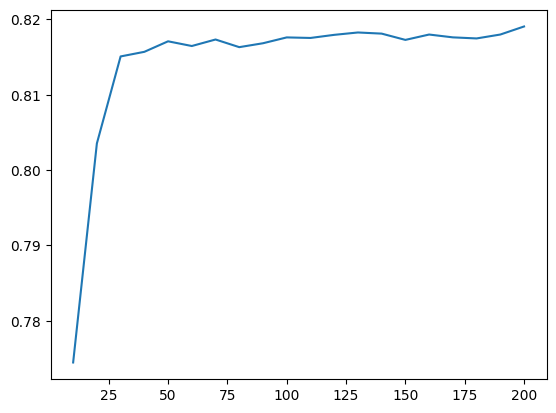

In [66]:
plt.plot(df_scores.n_estimators, df_scores.auc)

In [67]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators = n, max_depth=d, random_state = 1)
        rf.fit(x_train, y_train)
        y_pred = rf.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n, auc))

In [68]:
cols = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=cols)
df_scores.head()

,max_depth,n_estimators,auc
0,5,10,0.787699
1,5,20,0.797731
2,5,30,0.800305
3,5,40,0.799708
4,5,50,0.799878


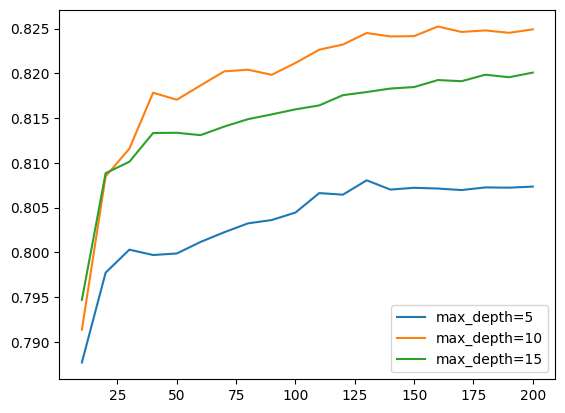

In [69]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)

plt.legend()

In [70]:
max_depth = 10

In [71]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators = n, max_depth=max_depth, min_samples_leaf=s, random_state = 1)
        rf.fit(x_train, y_train)
        y_pred = rf.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((s, n, auc))

In [72]:
cols = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=cols)
df_scores.head()

,min_samples_leaf,n_estimators,auc
0,1,10,0.791365
1,1,20,0.808496
2,1,30,0.811584
3,1,40,0.817839
4,1,50,0.817058


In [73]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
min_samples_leaf_values = [1, 3, 5, 10, 50]
list(zip(min_samples_leaf_values, colors))

[(1, 'black'), (3, 'blue'), (5, 'orange'), (10, 'red'), (50, 'grey')]

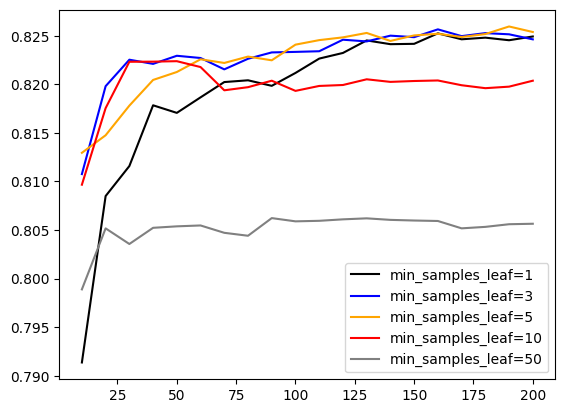

In [74]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
min_samples_leaf_values = [1, 3, 5, 10, 50]
for s, col in zip(min_samples_leaf_values, colors):

    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc,color=col, label='min_samples_leaf=%d' % s)

plt.legend()

In [75]:
min_sample_leaf = 3

In [76]:
rf = RandomForestClassifier(n_estimators = 200, max_depth=10, min_samples_leaf=3, random_state = 1)
rf.fit(x_train, y_train)


RandomForestClassifier(max_depth=10, min_samples_leaf=3, n_estimators=200,
                       random_state=1)

##### Gradient Boosting - XGBoost

In [77]:
import xgboost as xgb

In [78]:
features = dv.get_feature_names_out().tolist()  # convert ndarray → list

dtrain = xgb.DMatrix(x_train, label=y_train, feature_names=features)
dval   = xgb.DMatrix(x_val,   label=y_val,   feature_names=features)

In [79]:
xgb_params = {
    'eta' : 0.3,
    'max_depth' : 6,
    'min_child_weight' : 1,

    'objective' : 'binary:logistic',
    'nthreads' : 8,

    'seed' : 1,
    'verbosity' : 1,
}
model = xgb.train(xgb_params, dtrain, num_boost_round=200)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:31:15] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "nthreads" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [80]:
y_pred = model.predict(dval)

In [81]:
roc_auc_score(y_val, y_pred)

np.float64(0.8045064299726334)

In [103]:
%%capture output

watchlist = [(dtrain, 'train'), (dval, 'val')]
xgb_params = {
    'eta' : 0.3,
    'max_depth' : 6,
    'min_child_weight' : 1,

    'objective' : 'binary:logistic',
    'eval_metric' : 'auc',
    'nthreads' : 8,

    'seed' : 1,
    'verbosity' : 1,
}

model = xgb.train(xgb_params, dtrain, verbose_eval = 5, evals=watchlist, num_boost_round=200)

In [83]:
s = output.stdout

In [84]:
line = s.split('\n')[0]

In [85]:
line

'[0]\ttrain-auc:0.86632\tval-auc:0.77998'

In [86]:
line.split('\t')

['[0]', 'train-auc:0.86632', 'val-auc:0.77998']

In [87]:
num_iter, train_auc, val_auc = line.split('\t')

In [88]:
int(num_iter.strip('[]'))

0

In [89]:
float(train_auc.split(':')[1])

0.86632

In [90]:
float(val_auc.split(':')[1])

0.77998

In [91]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [96]:
df_score = parse_xgb_output(output)
df_score

,num_iter,train_auc,val_auc
0,0,0.86632,0.77998
1,5,0.93359,0.81150
2,10,0.95391,0.82002
3,15,0.97087,0.82220
4,20,0.97677,0.82239
5,25,0.98440,0.82074
6,30,0.98805,0.82061
7,35,0.99239,0.81804
8,40,0.99474,0.81732
9,45,0.99627,0.81413


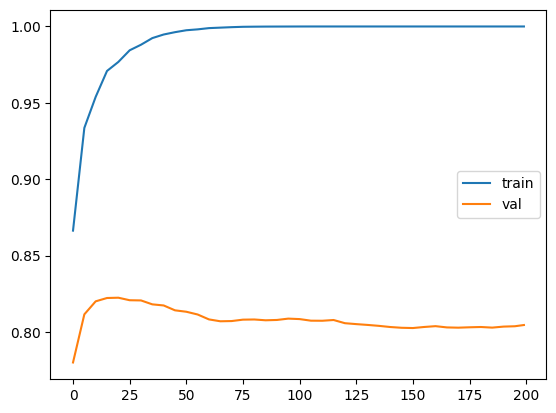

In [93]:
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

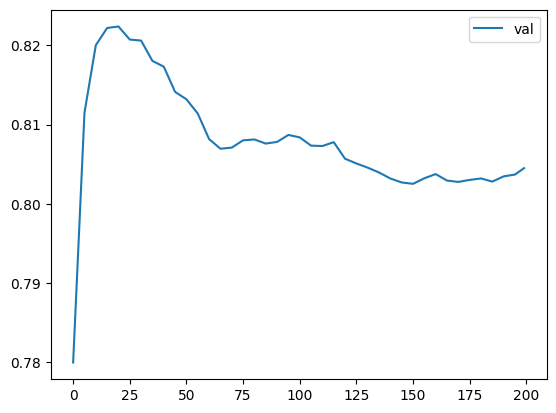

In [94]:
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

In [97]:
# XGB Parameter tuning

In [113]:
scores = {}

In [146]:
%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread':8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)


In [130]:
key  = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

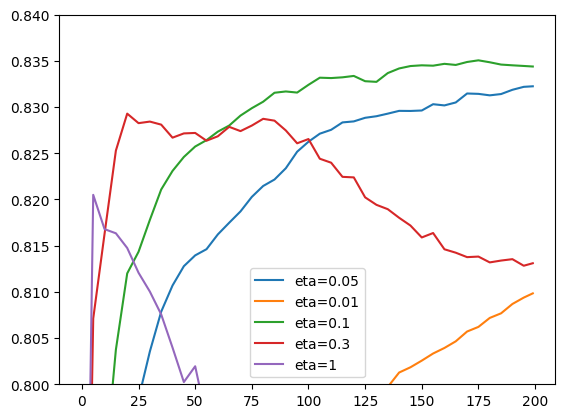

In [131]:
for key, df_score in scores.items():
  plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

In [111]:
# Train XGBoost models for each eta and store AUC results
scores = {} # dictionary to store results for each eta
etas = [0.01, 0.05, 0.1, 0.3, 1.0] # list of parameter values. in this case it is 'eta'.

for eta in etas:
    evals_result = {}

    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    model = xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=200,
        evals_result=evals_result
    )

    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'eta={eta}'
    scores[key] = df_results

In [144]:
# Tuning max depth
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=6'

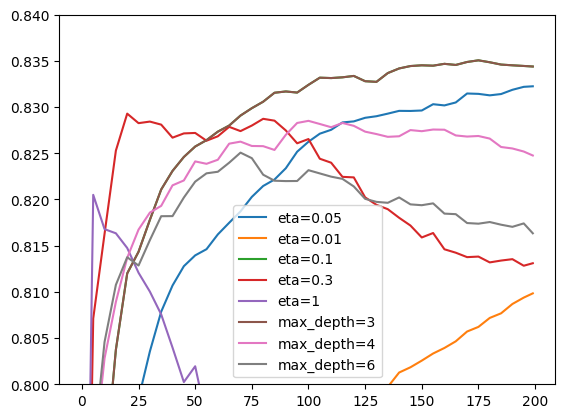

In [145]:
for key, df_score in scores.items():
  plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

In [147]:
# Tuning min_child_weight

In [149]:
%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 30,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [150]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)

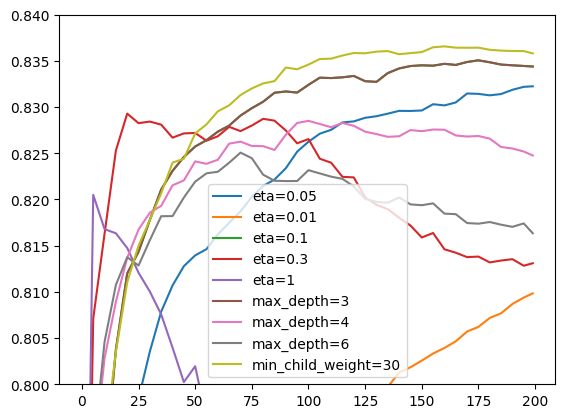

In [151]:
for key, df_score in scores.items():
  plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

In [153]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

In [158]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(x_train, y_train)
y_pred = dt.predict_proba(x_val)[:, 1]
roc_auc_score(y_val, y_pred)

np.float64(0.7854738320699426)

In [160]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=3,
                            random_state=1)
rf.fit(x_train, y_train)
y_pred = rf.predict_proba(x_val)[:, 1]
roc_auc_score(y_val, y_pred)

np.float64(0.8246258264512848)

In [163]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

np.float64(0.8351426460972124)

In [164]:
df_full_train = df_full_train.reset_index(drop=True)

y_full_train = (df_full_train.status == 'default').astype(int).values
del df_full_train['status']

In [165]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [169]:
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                    feature_names=dv.get_feature_names_out().tolist())

dtest = xgb.DMatrix(X_test, feature_names=dv.get_feature_names_out().tolist())

In [170]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [171]:
y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

np.float64(0.8290589414007137)